# Module A: train-test split, cross-validation, classification and regression metrics, confusion matrix, ROC-AUC

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     KFold, StratifiedKFold, cross_validate)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score)
 

In [3]:
# ---------------------------------------------------------------
data = load_breast_cancer()
X, y = data.data, data.target          # 1 = benign, 0 = malignant
print("Shape:", X.shape, "| Class counts:", np.bincount(y))
 

Shape: (569, 30) | Class counts: [212 357]


In [4]:
print("\n=== 1. TRAIN-TEST SPLIT ===")
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
print("Without stratify  train ratio:", np.bincount(y_tr) / len(y_tr))
print("Without stratify  test  ratio:", np.bincount(y_te) / len(y_te))
 
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("With stratify     train ratio:", np.bincount(y_tr) / len(y_tr))
print("With stratify     test  ratio:", np.bincount(y_te) / len(y_te))
 
# random_state ka asar: score split ke sath badalta hai
scores = []
for seed in range(10):
    a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=seed)
    m = Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=1000))])
    scores.append(m.fit(a, c).score(b, d))
print("Accuracy across 10 seeds: min=%.3f max=%.3f std=%.3f"
      % (min(scores), max(scores), np.std(scores)))


=== 1. TRAIN-TEST SPLIT ===
Without stratify  train ratio: [0.37142857 0.62857143]
Without stratify  test  ratio: [0.37719298 0.62280702]
With stratify     train ratio: [0.37362637 0.62637363]
With stratify     test  ratio: [0.36842105 0.63157895]
Accuracy across 10 seeds: min=0.965 max=0.991 std=0.008


In [5]:
print("\n=== 2. CROSS-VALIDATION ===")
pipe = Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=1000))])
 
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipe, X, y, cv=skf, scoring="accuracy")
print("Stratified 5-fold:", cv_scores.round(3),
      "mean=%.3f std=%.3f" % (cv_scores.mean(), cv_scores.std()))
 
kf = KFold(n_splits=5, shuffle=True, random_state=42)
print("Plain KFold mean: %.3f" % cross_val_score(pipe, X, y, cv=kf).mean())
 
# Multiple metrics ek sath
res = cross_validate(pipe, X, y, cv=skf, scoring=["accuracy", "f1", "roc_auc"])
for k in ["test_accuracy", "test_f1", "test_roc_auc"]:
    print(f"{k}: {res[k].mean():.3f}")
 
# DATA LEAKAGE demo: scaler ko poore data pe fit karna ghalat hai, kyunke
# test fold ki mean/std train mein "leak" ho jaati hai.
X_leaky = StandardScaler().fit_transform(X)                       # GHALAT
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_leaky, y, cv=skf).mean()
clean = cross_val_score(pipe, X, y, cv=skf).mean()                # SAHI (Pipeline)
print(f"Leaky CV: {leaky:.4f} | Pipeline CV: {clean:.4f}")


=== 2. CROSS-VALIDATION ===
Stratified 5-fold: [0.974 0.947 0.965 0.991 0.991] mean=0.974 std=0.017
Plain KFold mean: 0.977
test_accuracy: 0.974
test_f1: 0.979
test_roc_auc: 0.995
Leaky CV: 0.9737 | Pipeline CV: 0.9737


In [6]:
print("\n=== 3. CLASSIFICATION METRICS ===")
pipe.fit(X_tr, y_tr)
y_pred = pipe.predict(X_te)
 
tn, fp, fn, tp = confusion_matrix(y_te, y_pred).ravel()
acc = (tp + tn) / (tp + tn + fp + fn)
prec = tp / (tp + fp)
rec = tp / (tp + fn)
f1 = 2 * prec * rec / (prec + rec)
print(f"Manual : acc={acc:.3f} prec={prec:.3f} rec={rec:.3f} f1={f1:.3f}")
print(f"sklearn: acc={accuracy_score(y_te, y_pred):.3f} "
      f"prec={precision_score(y_te, y_pred):.3f} "
      f"rec={recall_score(y_te, y_pred):.3f} f1={f1_score(y_te, y_pred):.3f}")
print(classification_report(y_te, y_pred, target_names=data.target_names))
 
# Imbalanced data mein accuracy dhoka deti hai
rng = np.random.RandomState(0)
y_true_imb = np.array([1] * 5 + [0] * 95)           # 5% positive
y_dumb = np.zeros(100, dtype=int)                    # model hamesha 0 bole
print("Dumb model on 95/5 data -> accuracy:", accuracy_score(y_true_imb, y_dumb),
      "| recall:", recall_score(y_true_imb, y_dumb),
      "| f1:", f1_score(y_true_imb, y_dumb, zero_division=0))


=== 3. CLASSIFICATION METRICS ===
Manual : acc=0.982 prec=0.986 rec=0.986 f1=0.986
sklearn: acc=0.982 prec=0.986 rec=0.986 f1=0.986
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Dumb model on 95/5 data -> accuracy: 0.95 | recall: 0.0 | f1: 0.0



=== 4. CONFUSION MATRIX ===
[[41  1]
 [ 1 71]]


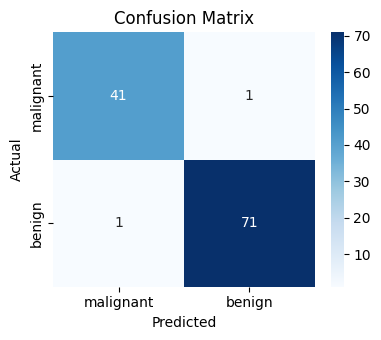

In [7]:
print("\n=== 4. CONFUSION MATRIX ===")
cm = confusion_matrix(y_te, y_pred)
print(cm)
plt.figure(figsize=(4, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.tight_layout(); plt.show()


=== 5. ROC-AUC ===
LogReg: AUC = 0.9954
RandomForest: AUC = 0.9931


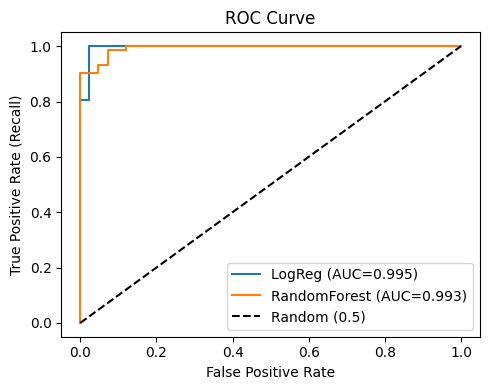

threshold=0.3: precision=0.973 recall=1.000
threshold=0.5: precision=0.986 recall=0.986
threshold=0.7: precision=0.985 recall=0.931
threshold=0.9: precision=0.984 recall=0.847


In [8]:
print("\n=== 5. ROC-AUC ===")
lr = Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=1000))]).fit(X_tr, y_tr)
rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_tr, y_tr)
 
plt.figure(figsize=(5, 4))
for name, model in [("LogReg", lr), ("RandomForest", rf)]:
    proba = model.predict_proba(X_te)[:, 1]          # positive class ki probability
    fpr, tpr, thr = roc_curve(y_te, proba)
    auc = roc_auc_score(y_te, proba)
    print(f"{name}: AUC = {auc:.4f}")
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random (0.5)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve"); plt.legend(); plt.tight_layout(); plt.show()
 
# Threshold badalne ka asar
proba = lr.predict_proba(X_te)[:, 1]
for t in [0.3, 0.5, 0.7, 0.9]:
    p = (proba >= t).astype(int)
    print(f"threshold={t}: precision={precision_score(y_te, p):.3f} "
          f"recall={recall_score(y_te, p):.3f}")

In [9]:
print("\n=== 6. REGRESSION METRICS ===")
Xd, yd = load_diabetes(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=42)
reg = LinearRegression().fit(Xd_tr, yd_tr)
yd_pred = reg.predict(Xd_te)
 
mae = mean_absolute_error(yd_te, yd_pred)
mse = mean_squared_error(yd_te, yd_pred)
rmse = np.sqrt(mse)
r2 = r2_score(yd_te, yd_pred)
print(f"MAE={mae:.2f} MSE={mse:.2f} RMSE={rmse:.2f} R2={r2:.3f}")
 
# Outlier ka asar: ek prediction jaan boojh kar bohat ghalat kar do
bad = yd_pred.copy(); bad[0] += 300
print("After one outlier -> MAE=%.2f RMSE=%.2f"
      % (mean_absolute_error(yd_te, bad), np.sqrt(mean_squared_error(yd_te, bad))))
# RMSE MAE se zyada badhta hai, kyunke error square hota hai.
 
# Regression ka CV
cv_r2 = cross_val_score(LinearRegression(), Xd, yd, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
print("5-fold R2:", cv_r2.round(3), "mean=%.3f" % cv_r2.mean())
# TODO: scoring="neg_mean_absolute_error" use karo. Negative kyun aata hai?
# (sklearn "higher is better" chahta hai, isliye loss ko negative karta hai.)
 
print("\nDone.")


=== 6. REGRESSION METRICS ===
MAE=42.79 MSE=2900.19 RMSE=53.85 R2=0.453
After one outlier -> MAE=44.38 RMSE=58.10
5-fold R2: [0.453 0.573 0.391 0.584 0.391] mean=0.478

Done.
